<a href="https://colab.research.google.com/github/moridin04/credit-card-fraud-detection/blob/main/credit-card-fraud-detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Exploring Anomaly Detection Techniques for Fraudulent Credit Card Transactions**

# **Environment Setup**

In [1]:
!pip install -q torch --index-url https://download.pytorch.org/whl/cpu

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

# **Importing Libraries**

In [2]:
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, roc_auc_score, average_precision_score
from scipy.stats import chi2

This study uses **PyTorch** for the reconstruction autoencoder rather than
TensorFlow: it is CPU-friendly, substantially lighter to install, and the
architecture is a simple dense encoder-decoder. Model interpretation uses
**permutation importance** rather than LIME, measured on the fraud class.

#**Loading Data**

In [3]:
from pathlib import Path

CANDIDATES = [
    Path("data/creditcard.csv"), # local repo layout
    Path("/content/data/creditcard.csv"), # Colab, after the move above
    Path("/content/creditcard.csv"),      # Colab, straight from the Files panel
]

DATA_PATH = next((p for p in CANDIDATES if p.exists()), None)

if DATA_PATH is None:
    raise FileNotFoundError(
        "creditcard.csv not found. Searched:\n  "
        + "\n  ".join(str(p) for p in CANDIDATES)
    )

print(f"Found: {DATA_PATH}  ({DATA_PATH.stat().st_size / 1e6:.1f} MB)")
cfd = pd.read_csv(DATA_PATH)
print(f"Loaded {len(cfd):,} rows x {cfd.shape[1]} columns")

Found: /content/creditcard.csv  (150.8 MB)
Loaded 284,807 rows x 31 columns


#**Exploration of Data**

In [4]:
cfd

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
284802,172786.0,-11.881118,10.071785,-9.834783,-2.066656,-5.364473,-2.606837,-4.918215,7.305334,1.914428,...,0.213454,0.111864,1.014480,-0.509348,1.436807,0.250034,0.943651,0.823731,0.77,0
284803,172787.0,-0.732789,-0.055080,2.035030,-0.738589,0.868229,1.058415,0.024330,0.294869,0.584800,...,0.214205,0.924384,0.012463,-1.016226,-0.606624,-0.395255,0.068472,-0.053527,24.79,0
284804,172788.0,1.919565,-0.301254,-3.249640,-0.557828,2.630515,3.031260,-0.296827,0.708417,0.432454,...,0.232045,0.578229,-0.037501,0.640134,0.265745,-0.087371,0.004455,-0.026561,67.88,0
284805,172788.0,-0.240440,0.530483,0.702510,0.689799,-0.377961,0.623708,-0.686180,0.679145,0.392087,...,0.265245,0.800049,-0.163298,0.123205,-0.569159,0.546668,0.108821,0.104533,10.00,0


This line displays the first few rows of the dataset to get a glimpse of the data.

**Shape, Columns, Null Values, and Data Types**

In [5]:
print(f"Shape:  {cfd.shape}\n")
print(f"Columns:  {cfd.columns}\n")
print(f"Null Values:  \n{cfd.isnull().sum()}\n")
print(f"Data Types: \n{cfd.dtypes}")

Shape:  (284807, 31)

Columns:  Index(['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10',
       'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20',
       'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount',
       'Class'],
      dtype='object')

Null Values:  
Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64

Data Types: 
Time      float64
V1        float64
V2        float64
V3        float64
V4        float64
V5        float64
V6        float64
V7        float64
V8        float64
V9        float64
V10       float64
V11       float64
V12       float64
V13       float64
V14       float64
V15       float64


**Summary Statistics for Numerical Features**

In [6]:
print(cfd.describe(include='all'))

                Time            V1            V2            V3            V4  \
count  284807.000000  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean    94813.859575  1.168375e-15  3.416908e-16 -1.379537e-15  2.074095e-15   
std     47488.145955  1.958696e+00  1.651309e+00  1.516255e+00  1.415869e+00   
min         0.000000 -5.640751e+01 -7.271573e+01 -4.832559e+01 -5.683171e+00   
25%     54201.500000 -9.203734e-01 -5.985499e-01 -8.903648e-01 -8.486401e-01   
50%     84692.000000  1.810880e-02  6.548556e-02  1.798463e-01 -1.984653e-02   
75%    139320.500000  1.315642e+00  8.037239e-01  1.027196e+00  7.433413e-01   
max    172792.000000  2.454930e+00  2.205773e+01  9.382558e+00  1.687534e+01   

                 V5            V6            V7            V8            V9  \
count  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05  2.848070e+05   
mean   9.604066e-16  1.487313e-15 -5.556467e-16  1.213481e-16 -2.406331e-15   
std    1.380247e+00  1.332271e+00  1.23709

This line provides summary statistics (mean, std, min, max, etc.) for all numerical features in the dataset.

**Class Distribution (Fraud vs. Non-Fraud)**

In [7]:
class_distribution = cfd['Class'].value_counts()
print("Class Distribution:")
print(class_distribution)

Class Distribution:
Class
0    284315
1       492
Name: count, dtype: int64


This code calculates and prints the distribution of the target variable Class, which indicates whether a transaction is fraudulent (1) or not (0).

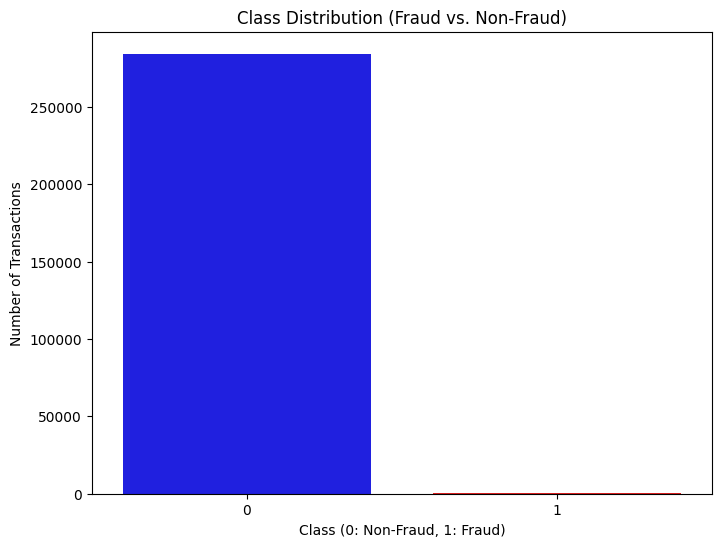

In [8]:
plt.figure(figsize=(8, 6))
sns.countplot(x='Class', data=cfd, hue='Class', palette=['blue', 'red'], legend=False)
plt.title('Class Distribution (Fraud vs. Non-Fraud)')
plt.xlabel('Class (0: Non-Fraud, 1: Fraud)')
plt.ylabel('Number of Transactions')
plt.show()

This code creates a count plot to visualize the distribution of fraudulent vs. non-fraudulent transactions.

**Class Distribution:**

**Non-Fraud**: 284,315 transactions

**Fraud**: 492 transactions

The dataset is highly imbalanced, with fraudulent transactions making up only 0.17% of the total transactions. This imbalance is typical in fraud detection datasets and poses a challenge for model training, as models may tend to predict the majority class (non-fraud) more frequently.

### **Distribution of Independent Variable**

**Distribution of Amount**

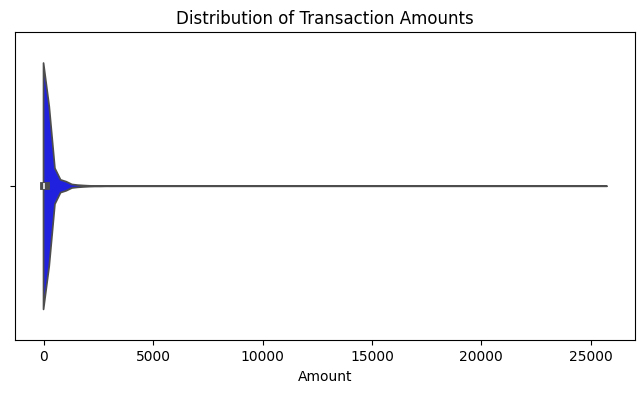

In [9]:
plt.figure(figsize=(8, 4))
sns.violinplot(x=cfd["Amount"], color="blue")
plt.title("Distribution of Transaction Amounts")
plt.xlabel("Amount")
plt.show()

This code creates a violin plot to visualize the distribution of transaction amounts.

The majority of transactions are of low amounts, with a long tail of higher-value transactions.

This is expected, as most credit card transactions are small, and high-value transactions are less frequent.

The presence of outliers in the Amount feature suggests that some transactions are significantly larger than the rest.

**Distribution of Time**

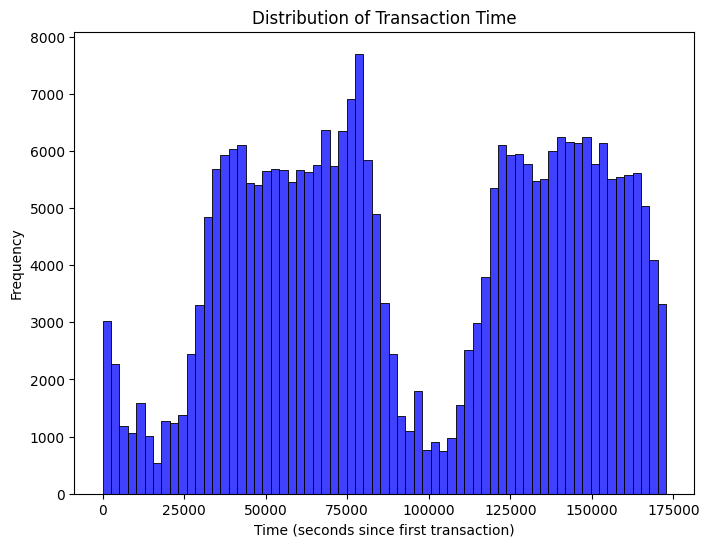

In [10]:
plt.figure(figsize=(8, 6))
sns.histplot(cfd['Time'], kde=False, color="blue")
plt.title('Distribution of Transaction Time')
plt.xlabel('Time (seconds since first transaction)')
plt.ylabel('Frequency')
plt.show()

This code creates a histogram to visualize the distribution of transaction times.

The Time feature represents the time elapsed since the first transaction.
The dataset spans roughly two days of European cardholder activity, so the
histogram shows a clear diurnal cycle with two pronounced peaks rather than a
flat distribution. This is why the temporal holdout matters: the test window
sits at a different point in the daily cycle than most of the training window.

**Histograms for Key Features (V1-V28, Amount, Time)**

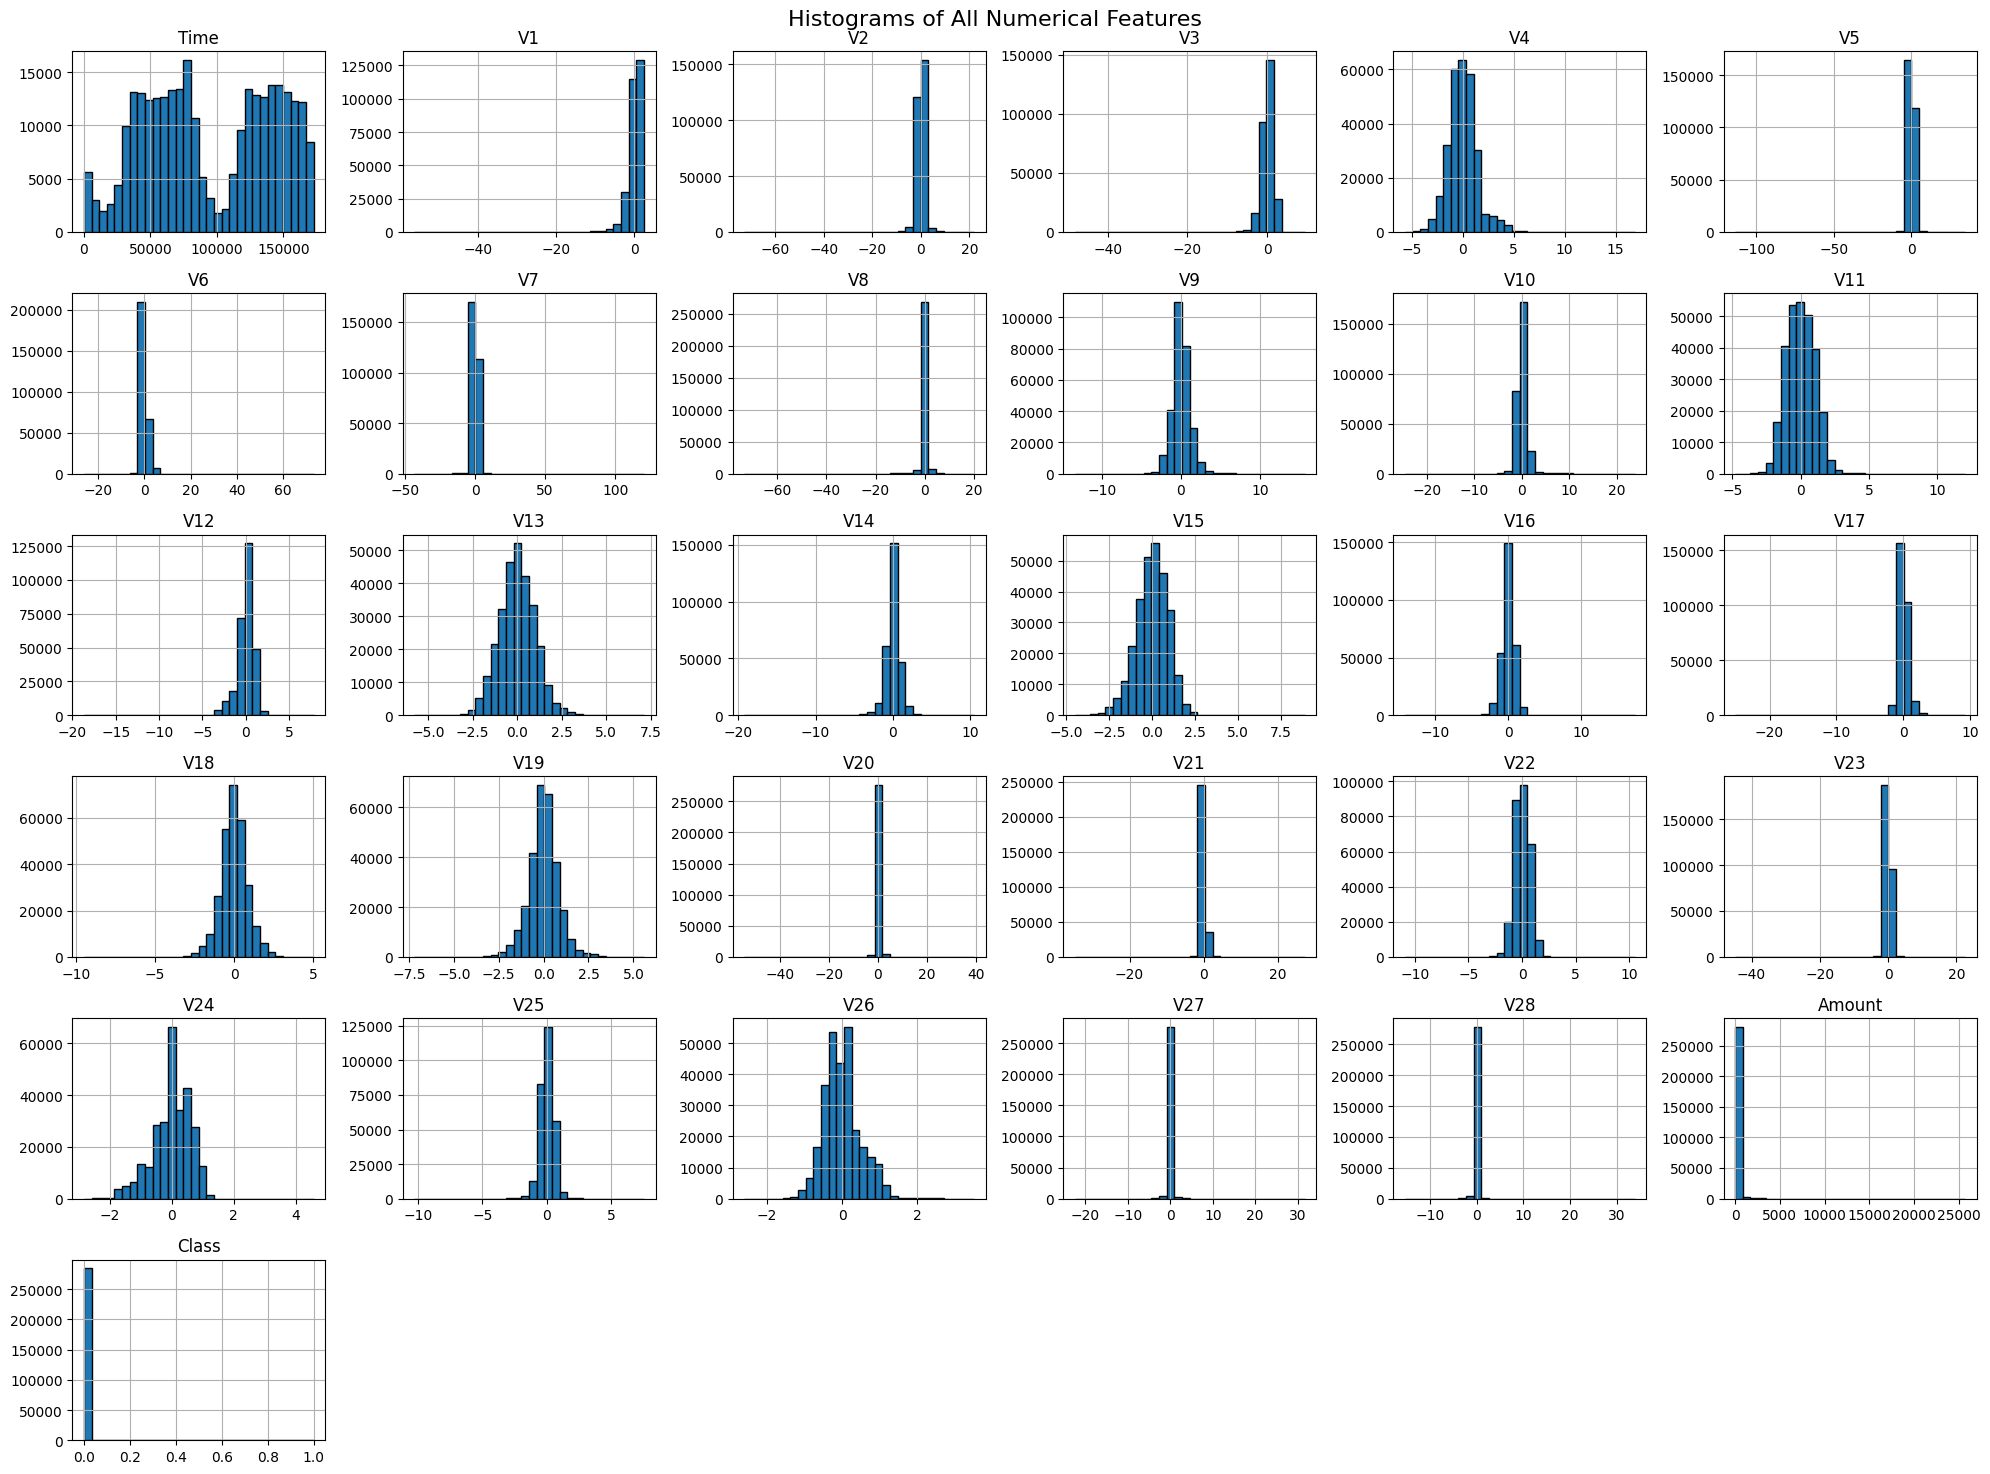

In [11]:
cfd.hist(bins=30, figsize=(20, 15), edgecolor='black')
plt.suptitle("Histograms of All Numerical Features", fontsize=16)
plt.tight_layout()
plt.show()

This code creates histograms for all numerical features in the dataset. Histograms for all numerical features (V1-V28, Amount, Time) are displayed.

The histograms show that most of the anonymized features (V1-V28) are centered around zero, with some features showing skewed distributions.

This is typical for PCA-transformed data, which is often used in fraud detection to anonymize sensitive information.

# **Pre-processing of Data**

**Checking of Null Values**

In [12]:
print("\nChecking for Null Values:")
cfd.isnull().sum()


Checking for Null Values:


,0
Time,0
V1,0
V2,0
V3,0
V4,0
V5,0
V6,0
V7,0
V8,0
V9,0


This code checks for null values in the dataset.

**Checking of Outliers**

In [13]:
Q1 = cfd['Amount'].quantile(0.25)
Q3 = cfd['Amount'].quantile(0.75)
IQR = Q3 - Q1

outliers = cfd[(cfd['Amount'] < (Q1 - 1.5 * IQR)) | (cfd['Amount'] > (Q3 + 1.5 * IQR))]
print(f"Number of outliers in 'Amount': {len(outliers)}")

Number of outliers in 'Amount': 31904


This code identifies outliers in the Amount column using the Interquartile Range (IQR) method.

**Checking of Duplicate Transactions**

In [14]:
cfd.duplicated()

,0
0,False
1,False
2,False
3,False
4,False
...,...
284802,False
284803,False
284804,False
284805,False


This code checks for duplicate rows in the dataset.

In [15]:
duplicate_counts = cfd.duplicated().value_counts()
print(duplicate_counts)

False    283726
True       1081
Name: count, dtype: int64


This code counts the number of duplicate rows.

In [16]:
dup_mask = cfd.duplicated(keep="first")
n_dup = int(dup_mask.sum())
n_dup_fraud = int(cfd.loc[dup_mask, "Class"].sum())

print(f"Exact duplicate rows: {n_dup:,}")
print(f"  of which fraudulent: {n_dup_fraud}")
print(f"Dropping these removes {n_dup_fraud} fraud cases "
      f"({n_dup_fraud / cfd['Class'].sum():.1%} of the minority class).")

cfd = cfd.loc[~dup_mask].reset_index(drop=True)
print(f"\nRows after removal: {len(cfd):,} | fraud: {cfd['Class'].sum()}")

Exact duplicate rows: 1,081
  of which fraudulent: 19
Dropping these removes 19 fraud cases (3.9% of the minority class).

Rows after removal: 283,726 | fraud: 473


This code removes duplicate rows from the dataset.

**Correlation Matrix for Numerical Features**

In [17]:
correlation_matrix = cfd.corr()

This code calculates the correlation matrix for numerical features.

**Correlation with the Target**

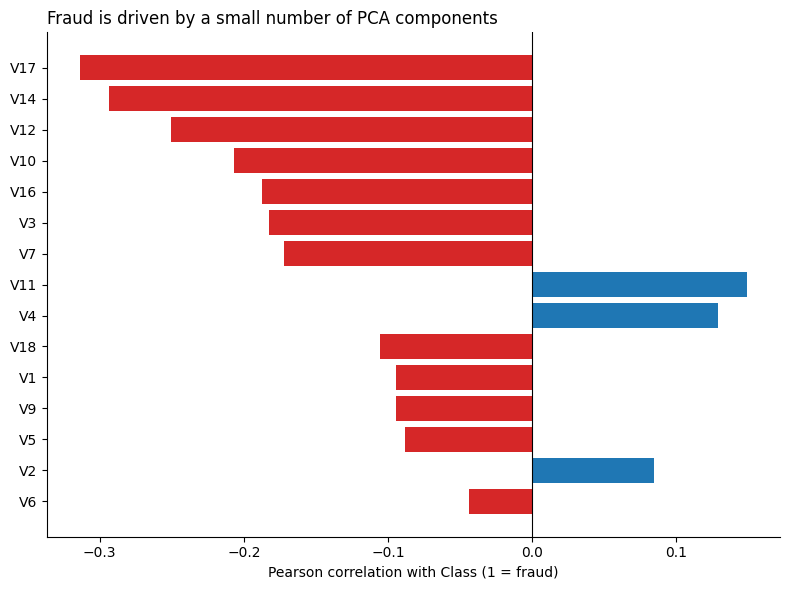

In [18]:
corr_with_target = cfd.corr(numeric_only=True)["Class"].drop("Class")
strong = corr_with_target.reindex(corr_with_target.abs().sort_values(ascending=False).index)[:15]

fig, ax = plt.subplots(figsize=(8, 6))
colors = ["#d62728" if v < 0 else "#1f77b4" for v in strong.values]
ax.barh(strong.index[::-1], strong.values[::-1], color=colors[::-1])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Pearson correlation with Class (1 = fraud)")
ax.set_title("Fraud is driven by a small number of PCA components", loc="left")
sns.despine()
plt.tight_layout()
plt.show()

This code visualizes the correlation matrix as a heatmap.

**Dropping Irrelevant Features**

In [19]:
threshold = 0.8
high_corr_features = set()
correlation_matrix = cfd.corr()

for i in range(len(correlation_matrix.columns)):
    for j in range(i):
        if abs(correlation_matrix.iloc[i, j]) > threshold:
            colname = correlation_matrix.columns[i]
            if colname != "Class":
                high_corr_features.add(colname)

print("Highly correlated features to drop:", high_corr_features)

cfd = cfd.copy()
cfd.drop(columns=high_corr_features, inplace=True)
print(f"Updated dataset shape: {cfd.shape}")

Highly correlated features to drop: set()
Updated dataset shape: (283726, 31)


This code identifies and drops highly correlated features based on a threshold.

**Train and Test**

In [20]:
FEATURES = ["Amount"] + [f"V{i}" for i in range(1, 29)]

df = cfd.sort_values("Time", kind="mergesort").reset_index(drop=True)

cut = int(len(df) * 0.80)
train_df, test_df = df.iloc[:cut].copy(), df.iloc[cut:].copy()

X_train, y_train = train_df[FEATURES], train_df["Class"].astype(int)
X_test,  y_test  = test_df[FEATURES],  test_df["Class"].astype(int)

print(f"Train: {len(X_train):,} rows | fraud {y_train.sum()} ({y_train.mean():.4%})")
print(f"Test:  {len(X_test):,} rows | fraud {y_test.sum()} ({y_test.mean():.4%})")
print(f"Time boundary: train ends {train_df['Time'].max():.0f}, "
      f"test begins {test_df['Time'].min():.0f}")
print("\nTest set is a future window: no test transaction occurred before "
      "the last training transaction.")

Train: 226,980 rows | fraud 399 (0.1758%)
Test:  56,746 rows | fraud 74 (0.1304%)
Time boundary: train ends 145233, test begins 145234

Test set is a future window: no test transaction occurred before the last training transaction.


# **Machine Learning**

In [21]:
class AmountThresholdBaseline:
    """Flag a transaction when Amount exceeds a threshold fitted on train."""
    name = "Baseline: Amount > threshold"
    def __init__(self, target_recall=0.10):
        self.target_recall = target_recall
    def fit(self, X, y):
        pos = X.loc[y == 1, "Amount"]
        self.threshold_ = float(np.quantile(pos, 1 - self.target_recall))
        return self
    def score(self, X):
        return X["Amount"].to_numpy(dtype=float)
    def predict(self, X, threshold=None):
        return (self.score(X) > self.threshold_).astype(int)


class AlwaysLegitimate:
    """Predict 'not fraud' for everything. The floor every model must beat."""
    name = "Baseline: always legitimate"
    def fit(self, X, y): return self
    def score(self, X): return np.zeros(len(X))
    def predict(self, X, threshold=None): return np.zeros(len(X), dtype=int)


def precision_at_k(y_true, scores, k):
    k = min(k, len(scores))
    top = np.argsort(-scores, kind="mergesort")[:k]
    return float(np.mean(np.asarray(y_true)[top] == 1))


def evaluate_model(name, model, X_test, y_test):
    """Full evaluation. Scores drive PR-AUC/ROC-AUC; labels come from the
    model's own calibrated threshold."""
    scores = model.score(X_test)
    preds = model.predict(X_test)

    tn, fp, fn, tp = confusion_matrix(y_test, preds, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall    = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
    f2 = 5 * precision * recall / (4 * precision + recall) if (4 * precision + recall) else 0.0

    return ({
        "Model": name,
        "Precision": precision, "Recall": recall, "F1": f1, "F2": f2,
        "PR_AUC": float(average_precision_score(y_test, scores)),
        "ROC_AUC": float(roc_auc_score(y_test, scores)),
        "Accuracy": float(np.mean(y_test == preds)),
        "Precision_at_0_1pct": precision_at_k(y_test, scores, max(1, int(0.001*len(scores)))),
        "Precision_at_1pct": precision_at_k(y_test, scores, int(0.01*len(scores))),
        "Alerts_per_10k": float(np.mean(preds == 1) * 10000),
        "TP": int(tp), "FP": int(fp), "FN": int(fn), "TN": int(tn),
    }, scores, preds)


# Baselines run FIRST - a model is only interesting relative to these.
baseline_model = AmountThresholdBaseline().fit(X_train, y_train)
baseline_result, baseline_scores, baseline_preds = evaluate_model(
    "Baseline: Amount > threshold", baseline_model, X_test, y_test)

always_result, _, _ = evaluate_model(
    "Baseline: always legitimate", AlwaysLegitimate(), X_test, y_test)

print("BASELINE CHECK")
print(pd.Series(baseline_result).to_string())

BASELINE CHECK
Model                  Baseline: Amount > threshold
Precision                                  0.002347
Recall                                     0.081081
F1                                         0.004563
F2                                         0.010519
PR_AUC                                     0.001451
ROC_AUC                                    0.385075
Accuracy                                   0.953865
Precision_at_0_1pct                             0.0
Precision_at_1pct                          0.005291
Alerts_per_10k                           450.428224
TP                                                6
FP                                             2550
FN                                               68
TN                                            54122


### **Isolation Forest**

In [22]:
CONTAMINATION = float(y_train.mean())   # measured prior, not a guess

if_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("model", IsolationForest(
        n_estimators=300,
        contamination=CONTAMINATION,
        random_state=42, n_jobs=-1,
    )),
])
_norm = X_train.loc[y_train == 0]
if_pipe["scale"].fit(_norm)
if_pipe["model"].fit(if_pipe["scale"].transform(X_train))

class IFDetector:
    name = "Isolation Forest"
    def fit(self, X):
        # Calibrate on TRAIN scores so the alert rate is controlled.
        # offset_ is unreliable at0.17% contamination: it flagged0 of 56,746.
        self.threshold_ = float(np.quantile(self.score(X), 1 - CONTAMINATION))
        return self
    def score(self, X):
        return if_pipe["model"].decision_function(
            if_pipe["scale"].transform(X)) * -1
    def predict(self, X, threshold=None):
        t = self.threshold_ if threshold is None else threshold
        return (self.score(X) >= t).astype(int)

if_model = IFDetector().fit(X_train)
if_result, if_scores, if_preds = evaluate_model(
    "Isolation Forest", if_model, X_test, y_test)

print(pd.Series(if_result).to_string())

Model                  Isolation Forest
Precision                           0.0
Recall                              0.0
F1                                  0.0
F2                                  0.0
PR_AUC                          0.04343
ROC_AUC                        0.944445
Accuracy                       0.997674
Precision_at_0_1pct                 0.0
Precision_at_1pct              0.065256
Alerts_per_10k                10.220985
TP                                    0
FP                                   58
FN                                   74
TN                                56614


In [23]:
print(f"TP={if_result['TP']}  FP={if_result['FP']}  "
      f"FN={if_result['FN']}  TN={if_result['TN']}")

TP=0  FP=58  FN=74  TN=56614


### **Autoencoders**

In [24]:
class AutoencoderDetector:
    """Reconstruction-error anomaly detector.

    Trained on NORMAL transactions only, with a linear output layer, and
    thresholded at a calibrated operating point rather than an arbitrary
    percentile.
    """
    name = "Autoencoder"

    def __init__(self, latent=4, hidden=(32, 16), epochs=40,
                 batch_size=512, lr=1e-3, val_fraction=0.15):
        self.latent, self.hidden, self.epochs = latent, hidden, epochs
        self.batch_size, self.lr, self.val_fraction = batch_size, lr, val_fraction
        self.scaler = StandardScaler()
        self.model = None

    def _build(self, n_features):
        enc, prev = [], n_features
        for w in self.hidden:
            enc += [nn.Linear(prev, w), nn.ReLU()]
            prev = w
        bottleneck = nn.Linear(prev, self.latent)
        dec, prev = [], self.latent
        for w in reversed(self.hidden):
            dec += [nn.Linear(prev, w), nn.ReLU()]
            prev = w
        # LINEAR output, not sigmoid. Inputs are z-scored and roughly
        # half-negative; a sigmoid decoder cannot reconstruct them.
        out = nn.Linear(prev, n_features)
        return nn.Sequential(*enc, bottleneck, *dec, out)

    def fit(self, X, y):
        torch.manual_seed(42)

        # FIX 1: train on normal rows only. Training on fraud teaches the
        # network to reconstruct fraud, which defeats the entire purpose.
        normals = X.loc[np.asarray(y) == 0].reset_index(drop=True)   # keep raw, indexable
        self.scaler.fit(normals)
        Xs = self.scaler.transform(normals).astype(np.float32)

        rng = np.random.default_rng(42)
        perm = rng.permutation(len(Xs))
        n_val = int(len(Xs) * self.val_fraction)
        val_idx, tr_idx = perm[:n_val], perm[n_val:]
        Xtr = torch.tensor(Xs[tr_idx])
        Xva = torch.tensor(Xs[val_idx])

        self.model = self._build(Xs.shape[1])
        opt = torch.optim.Adam(self.model.parameters(), lr=self.lr, weight_decay=1e-5)
        lossf = nn.MSELoss()
        loader = DataLoader(TensorDataset(Xtr), batch_size=self.batch_size, shuffle=True)

        best, best_state, patience = np.inf, None, 0
        for _ in range(self.epochs):
            self.model.train()
            for (xb,) in loader:
                opt.zero_grad()
                lossf(self.model(xb), xb).backward()
                opt.step()
            self.model.eval()
            with torch.no_grad():
                v = float(lossf(self.model(Xva), Xva))
            if v < best - 1e-5:
                best, patience = v, 0
                best_state = {k: t.clone() for k, t in self.model.state_dict().items()}
            else:
                patience += 1
                if patience >= 6:
                    break

        if best_state is not None:
            self.model.load_state_dict(best_state)

        # FIX 2: calibrate the threshold on held-out validation normals.
        # The old np.percentile(mse, 80) flagged 20% of ALL transactions,
        # which is where the 11,264 false positives came from.
        val_errors = self.reconstruction_error(normals.iloc[val_idx])  # raw -> scaled ONCE
        self.threshold_ = float(np.quantile(val_errors, 1 - CONTAMINATION * 4))
        return self

    def reconstruction_error(self, X):
        Xs = self.scaler.transform(X).astype(np.float32)
        self.model.eval()
        with torch.no_grad():
            recon = self.model(torch.tensor(Xs)).numpy()
        return np.mean((Xs - recon) ** 2, axis=1)

    def score(self, X):
        return self.reconstruction_error(X)

    def predict(self, X, threshold=None):
        t = self.threshold_ if threshold is None else threshold
        return (self.score(X) >= t).astype(int)


ae_model = AutoencoderDetector().fit(X_train, y_train)
ae_result, ae_scores, ae_preds = evaluate_model(
    "Autoencoder", ae_model, X_test, y_test)

print(pd.Series(ae_result).to_string())

Model                  Autoencoder
Precision                 0.124339
Recall                    0.635135
F1                        0.207965
F2                        0.348665
PR_AUC                    0.148808
ROC_AUC                   0.935951
Accuracy                  0.993691
Precision_at_0_1pct       0.303571
Precision_at_1pct         0.088183
Alerts_per_10k           66.612625
TP                              47
FP                             331
FN                              27
TN                           56341


### **Local Outlier Factor**

In [25]:
lof_scaler = StandardScaler()
lof_fit = lof_scaler.fit(X_train.loc[y_train == 0]) # normals only

lof = LocalOutlierFactor(
    n_neighbors=50,
    contamination=CONTAMINATION,
    novelty=True, n_jobs=-1,
)
lof.fit(lof_fit.transform(X_train.loc[y_train == 0]))

class LOFDetector:
    name = "Local Outlier Factor"
    def fit(self, X):
        self.threshold_ = float(np.quantile(self.score(X), 1 - CONTAMINATION))
        return self
    def score(self, X):
        return lof.decision_function(lof_scaler.transform(X)) * -1
    def predict(self, X, threshold=None):
        t = self.threshold_ if threshold is None else threshold
        return (self.score(X) >= t).astype(int)

This code initializes and trains a Local Outlier Factor (LOF) model for outlier detection.

In [26]:
lof_model = LOFDetector().fit(X_train)
lof_result, lof_scores, lof_preds = evaluate_model(
    "Local Outlier Factor", lof_model, X_test, y_test)

print(pd.Series(lof_result).to_string())

Model                  Local Outlier Factor
Precision                               0.0
Recall                                  0.0
F1                                      0.0
F2                                      0.0
PR_AUC                             0.016759
ROC_AUC                            0.895878
Accuracy                           0.997339
Precision_at_0_1pct                     0.0
Precision_at_1pct                  0.024691
Alerts_per_10k                    13.569238
TP                                        0
FP                                       77
FN                                       74
TN                                    56595


# **Evaluation of Model Performance**

**Selection of Best Performing Model**

RANKING QUALITY (threshold-free)



,PR_AUC,ROC_AUC,Precision_at_0_1pct,Precision_at_1pct
Model,,,,
Baseline: always legitimate,0.0013,0.5000,0.0000,0.0000
Baseline: Amount > threshold,0.0015,0.3851,0.0000,0.0053
Isolation Forest,0.0434,0.9444,0.0000,0.0653
Autoencoder,0.1488,0.9360,0.3036,0.0882
Local Outlier Factor,0.0168,0.8959,0.0000,0.0247



OPERATING POINTS (each model's own calibrated threshold)



,Precision,Recall,F1,F2,Alerts_per_10k,TP,FP,FN
Model,,,,,,,,
Baseline: always legitimate,0.0000,0.0000,0.0000,0.0000,0.0000,0,0,74
Baseline: Amount > threshold,0.0023,0.0811,0.0046,0.0105,450.4282,6,2550,68
Isolation Forest,0.0000,0.0000,0.0000,0.0000,10.2210,0,58,74
Autoencoder,0.1243,0.6351,0.2080,0.3487,66.6126,47,331,27
Local Outlier Factor,0.0000,0.0000,0.0000,0.0000,13.5692,0,77,74


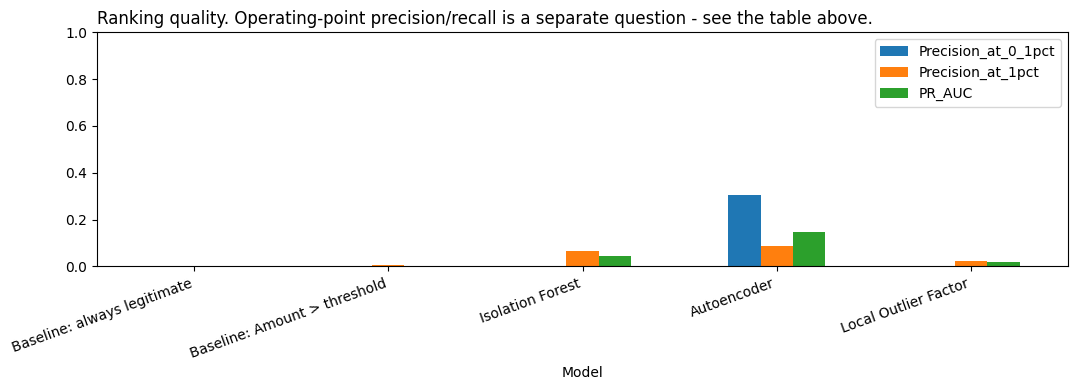

In [27]:
results_df = pd.DataFrame([always_result, baseline_result, if_result,
                           ae_result, lof_result])

rank_cols = ["Model", "PR_AUC", "ROC_AUC",
             "Precision_at_0_1pct", "Precision_at_1pct"]
print("RANKING QUALITY (threshold-free)\n")
display(results_df[rank_cols].set_index("Model").round(4))

# Operating points
op_cols = ["Model", "Precision", "Recall", "F1", "F2",
           "Alerts_per_10k", "TP", "FP", "FN"]
print("\nOPERATING POINTS (each model's own calibrated threshold)\n")
display(results_df[op_cols].set_index("Model").round(4))

ax = results_df.plot.bar(
    x="Model", y=["Precision_at_0_1pct", "Precision_at_1pct", "PR_AUC"],
    figsize=(11, 4), color=["#1f77b4", "#ff7f0e", "#2ca02c"], edgecolor="none")
ax.set_ylim(0, 1)
ax.set_title("Ranking quality. Operating-point precision/recall is a separate "
             "question - see the table above.", loc="left")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

**Feature Importance (Permutation)**

Instead of LIME, feature importance is measured by shuffling one feature at a
time and recording how much PR-AUC degrades. Unlike LIME's local surrogate,
this is measured on the actual fraud class and cannot produce a "probability"
that depends on the perturbation batch.

Feature  Importance      Std
 Amount    0.078828 0.001261
     V2    0.071158 0.001858
    V21    0.070915 0.001779
    V20    0.068341 0.001872
     V1    0.061806 0.001874
    V14    0.046808 0.002278
     V8    0.046335 0.001931
    V27    0.044165 0.002405
     V7    0.043170 0.002315
    V28    0.041879 0.001236


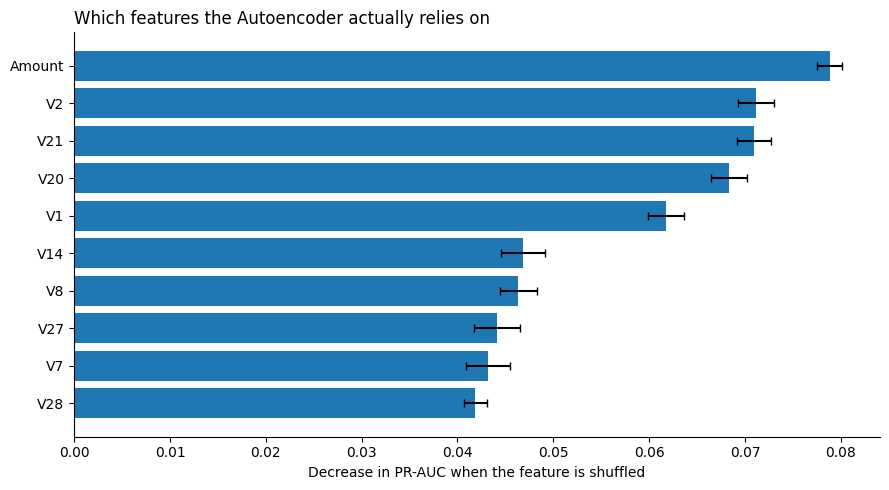

In [28]:
def permutation_importance_fraud(model, X, y, n_repeats=30, seed=42):
    """Custom permutation importance scored on PR-AUC (fraud class)."""
    rng = np.random.default_rng(seed)
    cols = list(X.columns)   # capture before converting
    X = np.asarray(X); y = np.asarray(y)
    base = average_precision_score(y, model.score(X))
    rows = []
    for j, col in enumerate(cols):
        drops = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[:, j] = rng.permutation(Xp[:, j])
            drops.append(base - average_precision_score(y, model.score(Xp)))
        rows.append((col, float(np.mean(drops)), float(np.std(drops))))
    return pd.DataFrame(rows, columns=["Feature", "Importance", "Std"]) \
             .sort_values("Importance", ascending=False)


import warnings
warnings.filterwarnings("ignore", message="X does not have valid feature names")

imp = permutation_importance_fraud(ae_model, X_test, y_test)
print(imp.head(10).to_string(index=False))

fig, ax = plt.subplots(figsize=(9, 5))
top = imp.head(10).iloc[::-1]
ax.barh(top["Feature"], top["Importance"], xerr=top["Std"],
        color="#1f77b4", capsize=3)
ax.set_xlabel("Decrease in PR-AUC when the feature is shuffled")
ax.set_title("Which features the Autoencoder actually relies on", loc="left")
sns.despine()
plt.tight_layout()
plt.show()

### **Statistical Tests**

In [29]:
def mcnemar_test(y_true, pred_a, pred_b):
    """Correct paired test for two classifiers on the same test set."""
    y_true = np.asarray(y_true); a = np.asarray(pred_a); b = np.asarray(pred_b)
    a_only = int(np.sum((a == y_true) & (b != y_true)))
    b_only = int(np.sum((a != y_true) & (b == y_true)))
    n = a_only + b_only
    if n == 0:
        return {"chi2": np.nan, "p": np.nan, "n_discordant": 0}
    chi2_stat = (abs(b_only - a_only) - 1) ** 2 / n
    return {"chi2": float(chi2_stat),
            "p": float(1 - chi2.cdf(chi2_stat, df=1)),
            "n_discordant": n,
            "a_only_correct": a_only, "other_only_correct": b_only}


def bootstrap_pr_auc_ci(y_true, scores, n_boot=2000, seed=42):
    """Percentile bootstrap CI. The test set holds 74 fraud cases, so a
    bare point estimate overstates certainty."""
    rng = np.random.default_rng(seed)
    y_true = np.asarray(y_true); scores = np.asarray(scores)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, len(y_true), len(y_true))
        if len(np.unique(y_true[idx])) < 2:
            continue
        vals.append(average_precision_score(y_true[idx], scores[idx]))
    return float(np.percentile(vals, 2.5)), float(np.percentile(vals, 97.5))


for name, preds in [("Autoencoder", ae_preds), ("Local Outlier Factor", lof_preds)]:
    t = mcnemar_test(y_test, if_preds, preds)
    print(f"Isolation Forest vs {name}: chi2={t['chi2']:.2f}, "
          f"p={t['p']:.4f}, discordant={t['n_discordant']}")

lo, hi = bootstrap_pr_auc_ci(y_test, if_scores)
print(f"\nIsolation Forest PR-AUC: {if_result['PR_AUC']:.4f} "
      f"(95% CI {lo:.4f} - {hi:.4f})")

Isolation Forest vs Autoencoder: chi2=145.47, p=0.0000, discordant=348
Isolation Forest vs Local Outlier Factor: chi2=2.40, p=0.1213, discordant=135

Isolation Forest PR-AUC: 0.0434 (95% CI 0.0301 - 0.0613)


In [30]:
for name, preds in [("Autoencoder", ae_preds), ("Local Outlier Factor", lof_preds)]:
    t = mcnemar_test(y_test, if_preds, preds)
    print(f"Isolation Forest vs {name}: chi2={t['chi2']:.2f}, "
          f"p={t['p']:.4f}, discordant={t['n_discordant']}")

print()
for name, res, sc in [("Isolation Forest", if_result, if_scores),
                      ("Autoencoder", ae_result, ae_scores),
                      ("Local Outlier Factor", lof_result, lof_scores)]:
    lo, hi = bootstrap_pr_auc_ci(y_test, sc)
    print(f"{name:22} PR-AUC {res['PR_AUC']:.4f}  (95% CI {lo:.4f} - {hi:.4f})")

Isolation Forest vs Autoencoder: chi2=145.47, p=0.0000, discordant=348
Isolation Forest vs Local Outlier Factor: chi2=2.40, p=0.1213, discordant=135

Isolation Forest       PR-AUC 0.0434  (95% CI 0.0301 - 0.0613)
Autoencoder            PR-AUC 0.1488  (95% CI 0.0982 - 0.2254)
Local Outlier Factor   PR-AUC 0.0168  (95% CI 0.0113 - 0.0254)


### **Cost Analysis**

In [31]:
COST_RATIO = 20   # stated assumption: a false positive costs 20x a false negative

print("Operational cost of the top-1% alert budget\n" + "=" * 46)
k = int(0.01 * len(y_test))
top = np.argsort(-if_scores, kind="mergesort")[:k]
tp = int((y_test.iloc[top] == 1).sum())
fp = k - tp
fn = int(y_test.sum()) - tp

print(f"Alerts raised        : {k:,}")
print(f"True fraud caught    : {tp}")
print(f"False alarms         : {fp:,}")
print(f"Fraud missed         : {fn}")
print(f"Ratio : {fp / tp:.1f} false alarms per true fraud")
print("-" * 46)
print(f"Cost at ratio {COST_RATIO:<4}   : {(fp * COST_RATIO + fn):,} units")
print(f"Cost of flagging none: {y_test.sum():,} units")

cost_now = fp * COST_RATIO + fn
cost_none = int(y_test.sum())
delta = (cost_now / cost_none - 1) * 100
print(f"Change vs flagging none: {delta:+.1f}%  "
      f"({'WORSE' if delta > 0 else 'better'})")

print("\nSensitivity to the cost assumption:")
for r in [1, 5, 10, 20, 50, 100]:
    print(f"  FP:FN = {r:>3}:x1  ->  {fp * r + fn:>10,} units")

Operational cost of the top-1% alert budget
Alerts raised        : 567
True fraud caught    : 37
False alarms         : 530
Fraud missed         : 37
Ratio : 14.3 false alarms per true fraud
----------------------------------------------
Cost at ratio 20     : 10,637 units
Cost of flagging none: 74 units
Change vs flagging none: +14274.3%  (WORSE)

Sensitivity to the cost assumption:
  FP:FN =   1:x1  ->         567 units
  FP:FN =   5:x1  ->       2,687 units
  FP:FN =  10:x1  ->       5,337 units
  FP:FN =  20:x1  ->      10,637 units
  FP:FN =  50:x1  ->      26,537 units
  FP:FN = 100:x1  ->      53,037 units


In [32]:
if all(fp * r + fn > y_test.sum() for r in [1, 5, 10, 20, 50, 100]):
    print("\nNo tested cost ratio makes this alert budget worthwhile.")


No tested cost ratio makes this alert budget worthwhile.


### **Threshold Sweep**

In [33]:
def threshold_sweep(y_true, scores, model_name):
    y = np.asarray(y_true, dtype=int)
    order = np.argsort(-scores, kind="mergesort")
    y_sorted = (y[order] == 1).astype(int)
    rows = []
    for pct in [0.05, 0.1, 0.25, 0.5, 1, 2, 5]:
        k = max(1, int(pct / 100 * len(y)))
        tp = int(y_sorted[:k].sum())
        rows.append({
            "Model": model_name,
            "Alert rate %": pct,
            "Alerts": k,
            "Precision": tp / k,
            "Recall": tp / y.sum(),
        })
    return pd.DataFrame(rows)


sweep = pd.concat([
    threshold_sweep(y_test, if_scores, "Isolation Forest"),
    threshold_sweep(y_test, ae_scores, "Autoencoder"),
], ignore_index=True)
display(sweep.round(4))

,Model,Alert rate %,Alerts,Precision,Recall
0,Isolation Forest,0.05,28,0.0000,0.0000
1,Isolation Forest,0.10,56,0.0000,0.0000
2,Isolation Forest,0.25,141,0.0284,0.0541
3,Isolation Forest,0.50,283,0.0530,0.2027
4,Isolation Forest,1.00,567,0.0653,0.5000
5,Isolation Forest,2.00,1134,0.0432,0.6622
6,Isolation Forest,5.00,2837,0.0219,0.8378
7,Autoencoder,0.05,28,0.2143,0.0811
8,Autoencoder,0.10,56,0.3036,0.2297
9,Autoencoder,0.25,141,0.2128,0.4054


# **Detection of Fraud**

In [34]:
def predict_transaction(model, amount=5000.0, time_val=100000, **v):
    """Score a single transaction with a model's own calibrated threshold.

    Returns (verdict, raw_score).

    Example:
        predict_transaction(if_model, amount=5000, time_val=100000)
        predict_transaction(if_model, amount=5000, V14=-9.5)

    NOTE: raw_score is NOT comparable across models. Isolation Forest
    returns roughly [-0.5, 0.5]; the autoencoder returns MSE ([0, inf)).
    Only verdicts are comparable.
    """
    base = {f: 0.0 for f in FEATURES}
    base["Amount"] = amount
    if "Time" in base:
        base["Time"] = time_val
    base.update({k: v[k] for k in v if k in base})   # ignore junk kwargs

    row = pd.DataFrame([base])[FEATURES]
    verdict = "FRAUD" if model.predict(row)[0] == 1 else "LEGITIMATE"
    return verdict, float(model.score(row)[0])


# A row with every V-feature at 0.0 is far off the data manifold.
# The verdict below is illustrative only, not evidence about the models.
for mdl in (if_model, ae_model, lof_model):
    print(f"{mdl.name:22} {predict_transaction(mdl)}")

Isolation Forest       ('LEGITIMATE', -0.2510262948066383)
Autoencoder            ('FRAUD', 11.322129249572754)
Local Outlier Factor   ('LEGITIMATE', -10.01387363068067)
